<a href="https://colab.research.google.com/github/Ali747711/CV/blob/master/PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install torch

In [ ]:
import torch

In [ ]:
print("CUDE: ", torch.cuda.is_available())

CUDE:  True


In [ ]:
scalar = torch.tensor(5)
print("scalar: ", scalar)
print("Shape: ", scalar.shape)

vector = torch.tensor([1, 2, 3])
print("vector: ", vector)
print("Shape: ", vector.shape)


scalar:  tensor(5)
Shape:  torch.Size([])
vector:  tensor([1, 2, 3])
Shape:  torch.Size([3])


In [ ]:
vector = torch.tensor([1, 2, 3]) # shape: 1D
print("vector: ", vector)
print("Number of dimentions: ", vector.ndim)
print("Shape: ", vector.shape)
print("Size: ", vector.size())

vector:  tensor([1, 2, 3])
Number of dimentions:  1
Shape:  torch.Size([3])
Size:  torch.Size([3])


In [ ]:
MATRIX = torch.tensor([[1, 2, 3], [4, 5, 6], [7, 8, 9]]) # shape: 2D
print(MATRIX)
print("Shape: ", MATRIX.shape)
print("Number of dimentions: ", MATRIX.ndim)
print("Size: ", MATRIX.size())

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])
Shape:  torch.Size([3, 3])
Number of dimentions:  2
Size:  torch.Size([3, 3])


In [ ]:
tensor3D = torch.stack([MATRIX, MATRIX + 10]) # shape: 3D
print("tensor3D: ", tensor3D)
print("Shape: ", tensor3D.shape)
print("Number of dimentions: ", tensor3D.ndim)
print("Size: ", tensor3D.size())

tensor3D:  tensor([[[ 1,  2,  3],
         [ 4,  5,  6],
         [ 7,  8,  9]],

        [[11, 12, 13],
         [14, 15, 16],
         [17, 18, 19]]])
Shape:  torch.Size([2, 3, 3])
Number of dimentions:  3
Size:  torch.Size([2, 3, 3])


In [ ]:
random_nums = torch.rand(2,3)
print("Random nums: ", random_nums)
print("Shape: ", random_nums.shape)
print("Number of dimentions: ", random_nums.ndim)
print("Size: ", random_nums.size())
print("Data_type: ", random_nums.dtype)
print("Device: ", random_nums.device)

Random nums:  tensor([[0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936]])
Shape:  torch.Size([2, 3])
Number of dimentions:  2
Size:  torch.Size([2, 3])
Data_type:  torch.float32
Device:  cpu


In [ ]:
print("Zeros", torch.zeros(3,3))


Zeros tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [ ]:
print("Ones", torch.ones(3,3))

Ones tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])


In [ ]:
x = torch.tensor([[1,2],[3,4]])
y = torch.tensor([[5,6],[7,8]])
print("Add: ", x + y)
print("==================")
print("Sub: ", x - y)
print("==================")
print("Mul: ", x * y)
print("==================")
print("Div: ", x / y)
print("==================")
print("Pow: ", x ** y)
print("==================")
print("Matrix mul: ", x @ y)
print("Matrix matmul: ", torch.matmul(x,y))


Add:  tensor([[ 6,  8],
        [10, 12]])
Sub:  tensor([[-4, -4],
        [-4, -4]])
Mul:  tensor([[ 5, 12],
        [21, 32]])
Div:  tensor([[0.2000, 0.3333],
        [0.4286, 0.5000]])
Pow:  tensor([[    1,    64],
        [ 2187, 65536]])
Matrix mul:  tensor([[19, 22],
        [43, 50]])
Matrix matmul:  tensor([[19, 22],
        [43, 50]])


### Note on Matrix Multiplication in PyTorch

There are two primary ways to perform multiplication with matrices in PyTorch:

1. **Element-wise Multiplication (`*` or `torch.mul`)**
   * Multiplies corresponding elements of two matrices of the same shape.
   * Example: For position $(0,0)$, it computes $x[0,0] \times y[0,0]$.
   * Formula:
     $$\begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix} * \begin{pmatrix} 5 & 6 \\ 7 & 8 \end{pmatrix} = \begin{pmatrix} 1 \times 5 & 2 \times 6 \\ 3 \times 7 & 4 \times 8 \end{pmatrix} = \begin{pmatrix} 5 & 12 \\ 21 & 32 \end{pmatrix}$$

2. **Matrix Multiplication / Dot Product (`@` or `torch.matmul`)**
   * Performs standard algebraic matrix multiplication where the rows of the first matrix are multiplied by the columns of the second matrix.
   * The number of columns in the first matrix must equal the number of rows in the second matrix.
   * Formula:
     $$\begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix} @ \begin{pmatrix} 5 & 6 \\ 7 & 8 \end{pmatrix} = \begin{pmatrix} (1 \times 5 + 2 \times 7) & (1 \times 6 + 2 \times 8) \\ (3 \times 5 + 4 \times 7) & (3 \times 6 + 4 \times 8) \end{pmatrix} = \begin{pmatrix} 19 & 22 \\ 43 & 50 \end{pmatrix}$$

# Neural Network

In [ ]:
import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural network
import matplotlib.pyplot as plt



In [ ]:
# Set up device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: ", device)

Using device:  cuda


In [ ]:
# Create weight and bias
weight = 0.7
bias = 0.3


# Create range values
start = 0
end = 1
step = 0.02

# Create x and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) # without unsequcen, errors will happen later on (shapes within linear layers)
y = weight * X + bias

# print("X: ", X)

# Split data
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

# print("X_train: ", X_train)
# print("y_train: ", y_train)

len(X_train), len(y_train), len(X_test), len(y_test)


(40, 40, 10, 10)

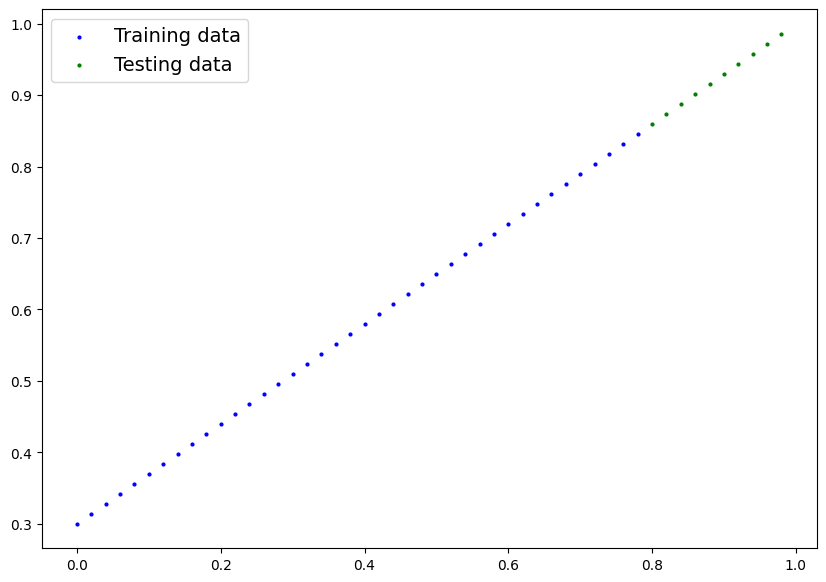

In [ ]:
def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):
  plt.figure(figsize=(10,7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  #Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot predictions in red
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14})
plot_predictions()

In [ ]:
# Subclass nn.Module to make our own model
class LinearRegressionModelV1(nn.Module):
  def __init__(self):
    super().__init__()

    # Use nn.Linear() for creating the model parameters
    self.linear_layer = nn.Linear(in_features=1, # Weight and bias
                                  out_features=1) # Linear => y = w * x + b

  # Define the forward computation (input data x flows through nn.Linear())
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

# Set manual seed when creating model (this is not always needed but is used for demonstration purpose, try commiting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV1()
model_1, model_1.state_dict()

(LinearRegressionModelV1(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [ ]:
loss_fn = nn.L1Loss() # MAE => Mean Absolute Error

# Create optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(), # optimize newly created model's parameter
                            lr=0.01) # Weight and bias

Text(0.5, 1.0, 'Prediction before training (red = random guesses)')

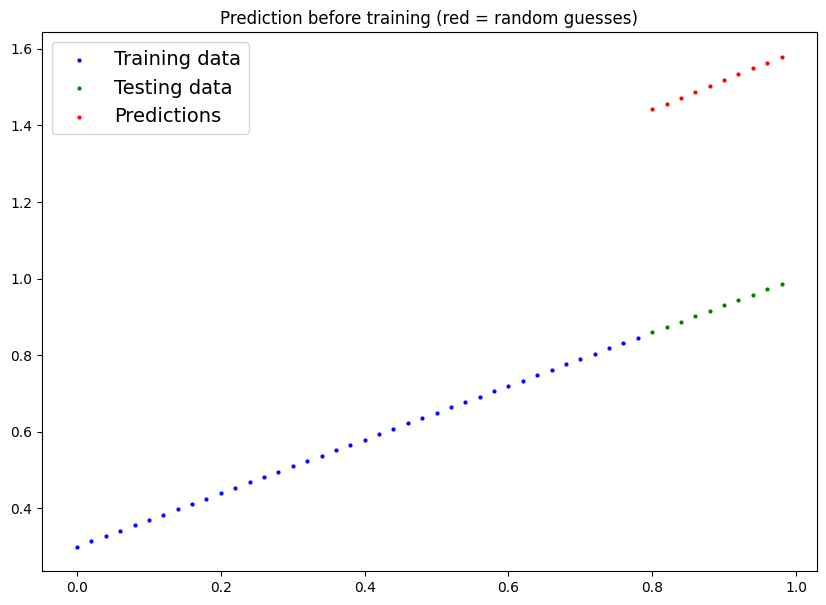

In [ ]:
# See model's untrained prediction (on test set)
model_1.eval()
with torch.inference_mode():
  untrained_preds = model_1(X_test)

plot_predictions(predictions=untrained_preds)
plt.title("Prediction before training (red = random guesses)")

In [ ]:
# Set the number of trains(epoches)
epochs = 1000

# Put data on the available device
# Without this, error will happen (not all model/data on device)
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

# Move model to the target device
model_1 = model_1.to(device)

for epoch in range(epochs):
  model_1.train() # Train mode is on by default after construction

  # 1. Forward pass
  y_pred = model_1(X_train) # model.forward(X_train)

  # 2. Calculate loss
  loss = loss_fn(y_pred, y_train)

  # 3. Optimizer zero grad
  optimizer.zero_grad()

  # 4. Loss backward
  loss.backward()

  # 5. Optimizer step
  optimizer.step()

  ## Testing
  model_1.eval() # put the model in evaluation mode for testing (inference)

  # 1. Forward pass
  with torch.inference_mode():
    test_pred = model_1(X_test)

    # 2. Calculate test loss
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 100 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 200 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 300 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 400 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 500 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 600 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 700 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 800 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 900 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882


In [ ]:
# Turn model into evalucation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
  y_preds = model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

Text(0.5, 1.0, 'Prediction after training (red = trained model)')

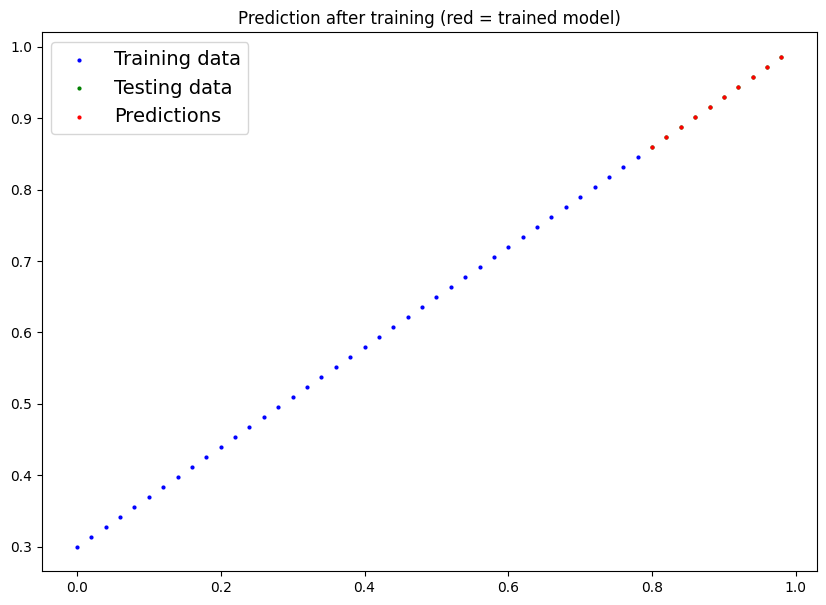

In [ ]:
plot_predictions(predictions=y_preds.cpu())
plt.title("Prediction after training (red = trained model)")

In [ ]:
torch.save(model_1.state_dict(), "01_pytorch_linear_regression.pth")

In [ ]:
loaded_model = LinearRegressionModelV1()
loaded_model.load_state_dict(torch.load("01_pytorch_linear_regression.pth"))
loaded_model

LinearRegressionModelV1(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)